# MU4MA015, Statistique, 2023-2024

Sorbonne Université, Master 1

Cours :  A. Ben-Hamou <br>
TP : A. Godichon, A. Guyader et M. Sangnier

## TP 1 : Statistique fréquentiste

# Table of contents
1. [Exercice 1 : Lois classiques](#part1)
1. [Exercice 2 : Loi des Grands Nombres](#part2)
1. [Exercice 3 : Théorème Central Limite](#part3)
1. [Exercice 4 : Régression linéaire simple](#part4)
1. [Exercice 5 : Convergence en loi](#part5)
1. [Exercice 6 : Comparaison d'estimateurs](#part6)
1. [Exercice 7 : Fonction de répartition empirique](#part7)
    - [Exercice 8 : Estimateur, test et fonction puissance](#part7sec1)


In [1]:
import numpy as np  # Vectors and matrices
from scipy import stats  # Probability distributions
import statsmodels.api as sm  # Linear regression
from statsmodels.sandbox.regression.predstd import wls_prediction_std  # Linear regression
import matplotlib.pyplot as plt  # Plots
from matplotlib import style
style.use('seaborn')  # Enable nice plots

/tmp/ipykernel_26270/2106305277.py:7: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  style.use('seaborn')  # Enable nice plots


# Exercice 1 : Lois classiques <a id="part1"></a>
>**Question 1.**
Afficher sur le même graphique les densités des lois $\chi^2_{50}$ et $\mathcal{N}(50,100)$.
On prendra soin d'agrémenter la figure de toutes les indications utiles (titre, légende…).
>
>Que constatez-vous ? Comment pouvez-vous le justifier ?

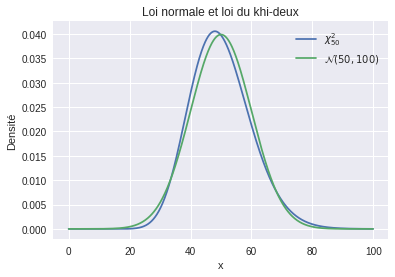

In [2]:
# Answer
ddl = 50

chi2 = stats.chi2(df=ddl)
norm = stats.norm(loc=ddl, scale=np.sqrt(2*ddl))

x = np.arange(0, 2*ddl, step=0.1)

plt.plot(x, chi2.pdf(x), label=f"$\\chi^2_{{{ddl}}}$")
# Compléter
plt.plot(x, norm.pdf(x), label=f"$\\mathcal{{N}}({ddl},{2*ddl})$")
plt.legend()
plt.xlabel('x')
plt.ylabel('Densité')
# Fin compléter
plt.title("Loi normale et loi du khi-deux");

**Answer**

On se souvient que si $(X_n)_{n \ge 1}$ est une suite de variables aléatoires indépendantes suivant la loi $\mathcal N(0, 1)$,
$\sum_{i=1}^n X_i^2 \sim \chi_n^2$.
Par ailleurs, le TCL indique que
$$
    \sqrt n \left( \frac 1n \sum_{i=1}^n X_i^2 - \mathbb E[X_1^2] \right) \xrightarrow[n\to\infty]{\mathcal L} \mathcal N \left(0, \mathbb V(X_1^2) \right),
$$
i.e.
$$
    \frac{1}{\sqrt n} \left( \sum_{i=1}^n X_i^2 - n \right) \xrightarrow[n\to\infty]{\mathcal L} \mathcal N \left(0, 2 \right).
$$
Ainsi, $\sum_{i=1}^n X_i^2 \overset{\mathcal L}{\approx} \mathcal N \left(n, 2n \right)$ losque $n$ est grand.

>**Question 2.**
Afficher sur le même graphique les densités des lois $\mathcal{T}_{5}$, $\mathcal{T}_{30}$ et $\mathcal{N}(0,1)$.
>
>Que constatez-vous ? Comment pouvez-vous le justifier ?

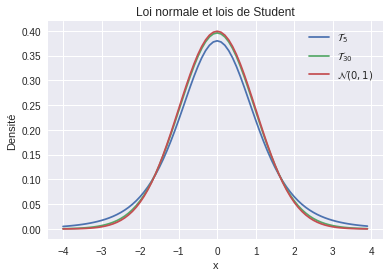

In [3]:
# Answer
d1 = 5
d2 = 30

t1 = stats.t(df=d1)
t2 = stats.t(df=d2)
# Compléter
norm = stats.norm()

x = np.arange(-4, 4, step=0.1)

plt.plot(x, t1.pdf(x), label=f"$\\mathcal{{T}}_{{{d1}}}$")
plt.plot(x, t2.pdf(x), label=f"$\\mathcal{{T}}_{{{d2}}}$")
plt.plot(x, norm.pdf(x), label=f"$\\mathcal{{N}}(0,1)$")  
plt.legend()
plt.xlabel('x')
plt.ylabel('Densité')
# Fin compléter
plt.title("Loi normale et lois de Student");

**Answer**

Soient $X \sim \mathcal N(0, 1)$ et $Y \sim \chi_d^2$ deux variables aléatoires indépendantes.
Par définition, la loi $\mathcal T_d$ est celle de la variable $\frac{X}{\sqrt{Y/d}}$, avec $\sqrt{Y/d} \xrightarrow[d\to\infty]{\mathbb P} 1$.
Le théorème de Slutsky assure donc que $\frac{X}{\sqrt{Y/d}} \xrightarrow[d\to\infty]{\mathcal L} \mathcal N(0, 1)$.

>**Question 3.**
Afficher sur le même graphique les densités de la loi de Fisher $\mathcal{F}^3_{20}$ et d'un $\frac{\chi_3^2}{3}$. On rappelle que si $X$ suit une loi avec les paramètres par défaut, alors la variable $Y=$ `scale` $X$+`loc`suit la loi dilatée translatée. 
>
>Que constatez-vous ? Comment pouvez-vous le justifier ?

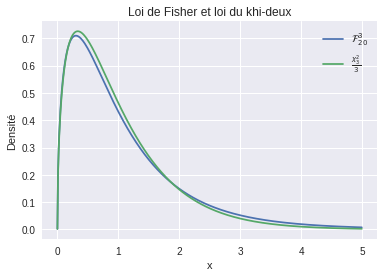

In [4]:
# Answer
d1 = 3
d2 = 20

f = stats.f(d1, d2)
# Compléter
chi = stats.chi2(df=d1, scale=1/3)

x = np.arange(1e-6, 5, step=0.01)

plt.plot(x, f.pdf(x), label=f"$\\mathcal{{F}}^{{{d1}}}_{{{d2}}}$")
# Fin compléter
plt.plot(x, chi.pdf(x), label=f"$\\frac{{\\chi^2_{{{d1}}}}}{{{d1}}}}}$")
plt.legend()
plt.xlabel('x')
plt.ylabel('Densité')
plt.title("Loi de Fisher et loi du khi-deux");

**Answer**

Soient $X \sim \chi_p^2$ et $Y \sim \chi_d^2$ deux variables aléatoires indépendantes.
Par définition, la loi $\mathcal F_d^p$ est celle de la variable $\frac{X/p}{Y/d}$, avec $Y/d \xrightarrow[d\to\infty]{\mathbb P} 1$.
Le théorème de Slutsky assure donc que $\frac{X/p}{Y/d} \xrightarrow[d\to\infty]{\mathcal L} \frac{\chi_p^2}{p}$.

# Exercice 2 : Loi des Grands Nombres <a id="part2"></a>
>**Question 1.**
Illustrer la Loi des Grands Nombres sur la loi Beta de paramètres $(\alpha, \beta) = (2, 5)$. Indication : pour calculer les moyennes successives, on pourra utiliser la fonction `cumsum`.

Support de la loi Beta : (0.0, 1.0)


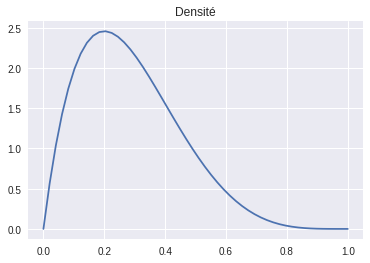

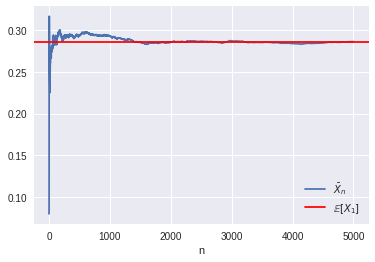

In [5]:
# Answer
dist = stats.beta(a=2, b=5)
print("Support de la loi Beta :", dist.support())

x = np.linspace(0, 1)
plt.plot(x, dist.pdf(x))
plt.title("Densité")

n = 5000
X = dist.rvs(size=n)
fig = plt.figure()

# Compléter
means = X.cumsum() / np.arange(1, n+1)

plt.plot(means, label="$\\bar{{X}}_n$")
# Fin compléter
plt.axhline(dist.mean(), color='red', label="$\\mathbb{{E}} [X_1]$")
plt.xlabel('n')
plt.legend();

Exemple :

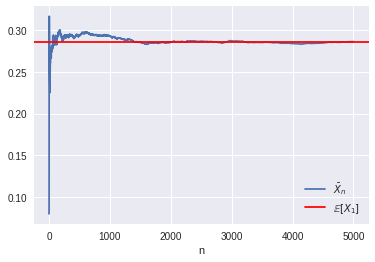

In [6]:
fig

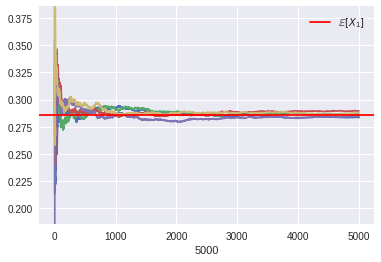

In [7]:
# Answer
# With several curves
N, n = 5, 5000
X = dist.rvs(size=(N, n))

means = X.cumsum(axis=1) / np.arange(1, n+1)

plt.figure()
for row in means:
    plt.plot(row)
    
plt.axhline(dist.mean(), color='red', label=r"$\mathbb{E} [X_1]$")
plt.xlabel(n)
plt.ylim((dist.mean()-0.1, dist.mean()+0.1))
plt.legend();


>**Question 2.**
Faire de même avec la loi de Cauchy. On tracera plusieurs trajectoires.

Support de la loi de Cauchy : (-inf, inf)


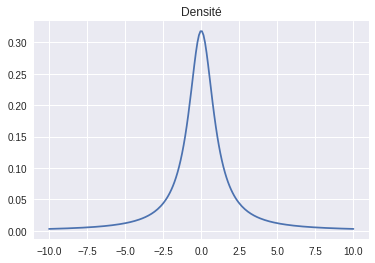

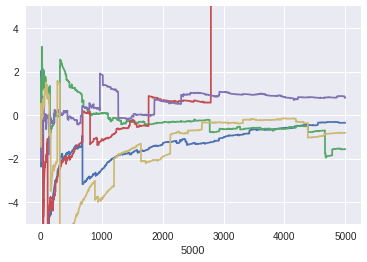

In [8]:
# Answer
dist = stats.cauchy()
print("Support de la loi de Cauchy :", dist.support())

x = np.linspace(-10, 10, num=200)
plt.plot(x, dist.pdf(x))
plt.title("Densité")

N, n = 5, 5000
X = dist.rvs(size=(N, n))
# Compléter


means = X.cumsum(axis=1) / np.arange(1, n+1)

plt.figure()
for row in means:
    plt.plot(row)
plt.xlabel(n)
plt.ylim((-5, 5));
# Fin compléter

# Exercice 3 : Théorème Central Limite <a id="part3"></a>
> Afficher la densité de probabilité de la loi Beta de paramètres $\alpha=0.5$ et $\beta=0.5$,
puis illustrer le Théorème Central Limite à l'aide d'histogrammes.
>
>On rappelle qu'un histogramme est un estimateur de la densité et que le lemme de Scheffé assure que la convergence simple des densités implique la convergence en loi.
>
>**Lemme de Scheffé**
>>Soient $(X_n)_{n\ge 1}$ une suite de variables aléatoires de densités $(f_n)_{n\ge 1}$ par rapport à une mesure dominante $\mu$
et $X$ une variable aléatoire de densité $f$ par rapport à $\mu$.
Si $(f_n)_{n\ge 1}$ converge simplement $\mu$-presque partout vers $f$, alors
$$
X_n \underset{n \to \infty}{\overset{\mathcal{L}}{\longrightarrow}} X.
$$

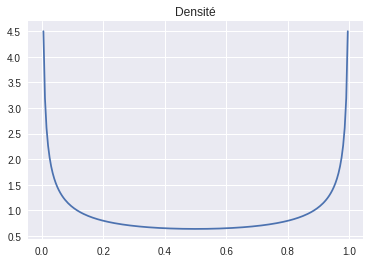

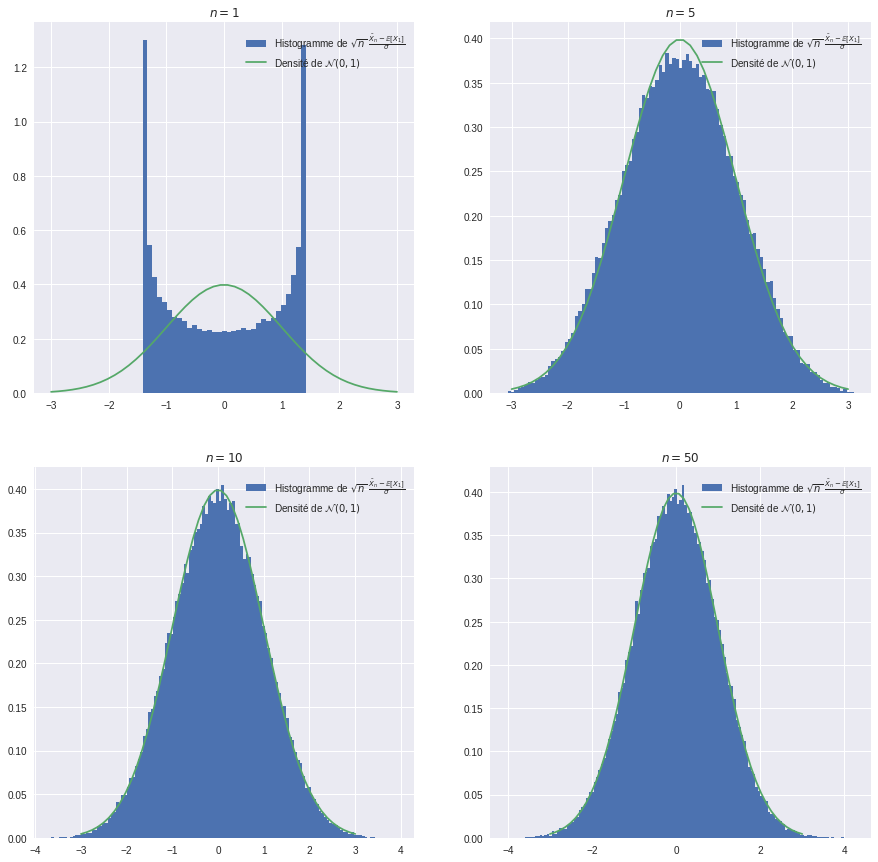

In [9]:
# Answer
dist = stats.beta(a=.5, b=.5)
norm = stats.norm()

x = np.linspace(0, 1, num=200)
plt.plot(x, dist.pdf(x))
plt.title("Densité")

N = 100000
x = np.linspace(-3, 3)

fig_hist = plt.figure(figsize=(15, 15))
for i, n in enumerate([1, 5, 10, 50]):
    # Compléter
    X = dist.rvs(size=(N, n))

    means = X.mean(axis=1)
    rv = np.sqrt(n) * (means - dist.mean()) / dist.std()
    # Fin compléter
    
    plt.subplot(2, 2, i+1)
    plt.hist(rv, bins='auto', density=True, label="Histogramme de $\\sqrt{{n}}\\ \\frac{{\\bar{{X}}_n - \\mathbb{{E}}[X_1]}}{{\\sigma}}$")  # normed=True for old versions
    plt.plot(x, norm.pdf(x), label="Densité de $\\mathcal{{N}}(0, 1)$")
    plt.legend()
    plt.title("$n = %d$" % n)

Exemple :

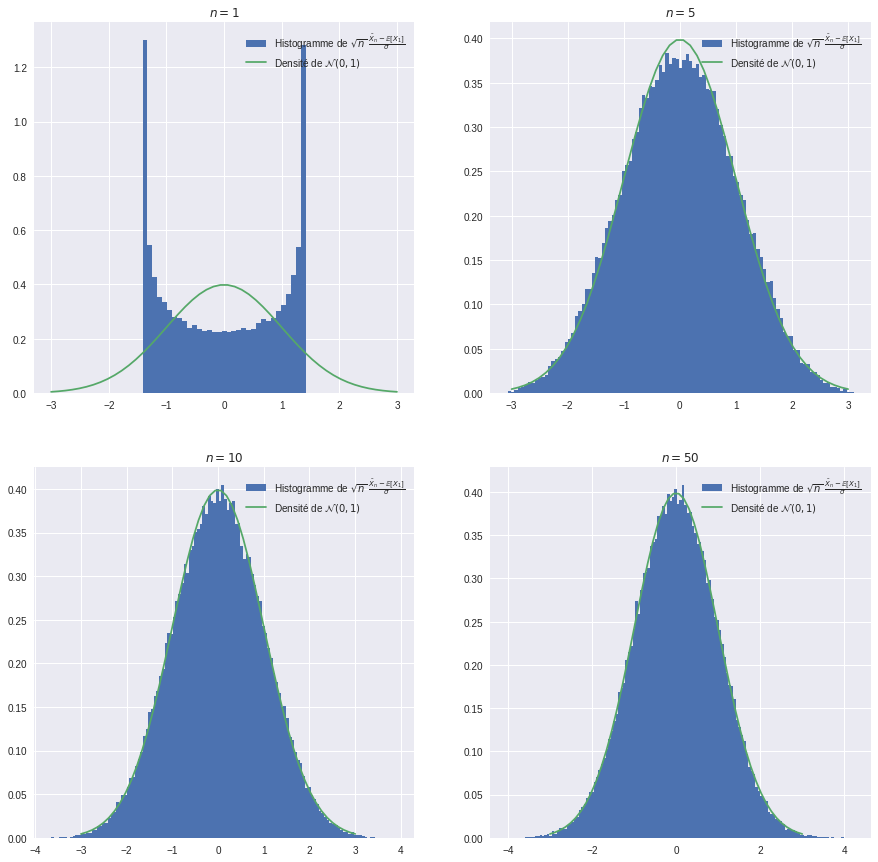

In [10]:
fig_hist

# Exercice 4 : Régression linéaire simple <a id="part4"></a>
>Considérons le modèle définissant, pour tout $i \in \{1, \dots, n\}$, les observations $$Y_i = a + b t_i  + \varepsilon_i,$$ où $t_1, \dots, t_n$ sont des données figées, $\varepsilon_1, \dots, \varepsilon_n$ sont des variables aléatoires i.i.d. de loi $\mathcal{N}(0, \sigma^2)$.
On cherche à estimer les paramètres inconnus $\beta=(a, b)$ et $\sigma^2$.

In [11]:
# Generate data
n = 50
t = np.linspace(0, 10, n)
X = np.column_stack((np.ones((n)),t))

beta = [2, -1]
y_true = X @ beta 

sigma = 2
noise = stats.norm(scale=sigma)
y = y_true + noise.rvs(size=n)

>**Question 1.**
Afficher en fonction de $(t_i)_{1 \le i \le n}$ les observations $(Y_i)_{1 \le i \le n}$ et la « vraie » droite $y = a + b t$.

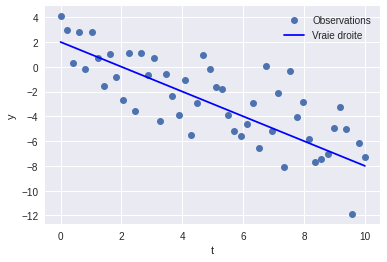

In [12]:
# Answer
# Compléter
plt.plot(t, y, 'o', label="Observations")
plt.plot(t, y_true, 'b-', label="Vraie droite")
# Fin compléter
plt.xlabel('t')
plt.ylabel('y')
plt.legend();

>**Question 2.**
Résoudre le problème de régression linéaire avec la routine `sm.OLS` et afficher le tableau de résultats.

In [13]:
# Answer
# Compléter
model = sm.OLS(y, X)
res = model.fit()
# Fin compléter
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.600
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     71.96
Date:                Thu, 19 Oct 2023   Prob (F-statistic):           4.14e-11
Time:                        13:26:03   Log-Likelihood:                -108.46
No. Observations:                  50   AIC:                             220.9
Df Residuals:                      48   BIC:                             224.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7396      0.602      2.888      0.006       0.529       2.951
x1            -0.8804      0.104     -8.483      0.000      -1.089      -0.672
==============================================================================
Omnibus:                        0.387   Durbin-Watson:                   2.379
Prob(Omnibus):                  0.824   Jarque-Bera (JB):                0.553
Skew:                          -0.094   Prob(JB):                        0.758
Kurtosis:                       2.521   Cond. No.                         11.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

>**Question 3.**
Retrouver par le calcul les valeurs des réalisations des estimateurs des moindres carrés $\hat \beta$ et $\hat \sigma_n^2$ donnés ci-dessus, c'est-à-dire :

In [14]:
print("Estimateur beta :", res.params)
print("Estimateur sigma2 :", res.scale)

Estimateur beta : [ 1.73964941 -0.88044176]
Estimateur sigma2 : 4.671719824372725


In [15]:
# Answer
inv = np.linalg.inv(X.T @ X)
# Compléter
H = X @ inv @ X.T  # Hat matrix

hat_beta = inv @ X.T @ y
# estim = X @ hat_beta
estim = H @ y
hat_sigma2 = np.linalg.norm(y - estim)**2 / (n-2)
# Fin compléter

print("Estimateur beta :", hat_beta)
print("Estimateur sigma2 :", hat_sigma2)

Estimateur beta : [ 1.73964941 -0.88044176]
Estimateur sigma2 : 4.671719824372727


>**Question 4.**
Ajouter sur le graphe précédent la droite estimée $y=\hat{a}+\hat{b}t$.

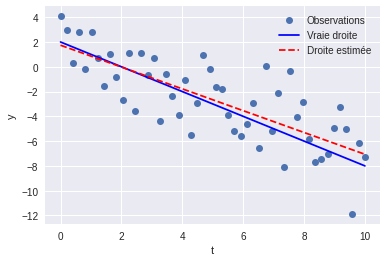

In [16]:
# Answer
# Compléter
plt.plot(t, y, 'o', label="Observations")
plt.plot(t, y_true, 'b-', label="Vraie droite")
plt.plot(t, estim, 'r--', label="Droite estimée")
# Fin compléter
plt.xlabel('t')
plt.ylabel('y')
plt.legend();

>**Question 5.**
Calculer et ajouter à la figure l'hyperbole de prédiction au niveau $(1-\alpha)$ pour $\alpha = 5\%$.

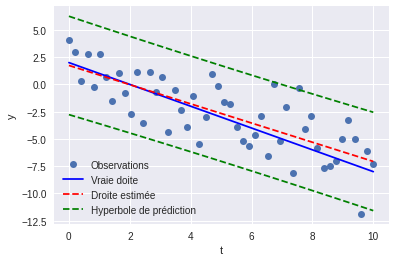

In [17]:
# Answer
stu = stats.t(n-2)
q = stu.ppf(1-0.05/2)
# Compléter
dev = q * np.sqrt(hat_sigma2 * (1 + np.diag(H)))

plt.plot(t, y, 'o', label="Observations")
plt.plot(t, y_true, 'b-', label="Vraie doite")
plt.plot(t, estim, 'r--', label="Droite estimée")
plt.plot(t, estim + dev, 'g--', label="Hyperbole de prédiction")
plt.plot(t, estim - dev, 'g--')
# Fin compléter
plt.xlabel('t')
plt.ylabel('y')
plt.legend();

# Exercice 5 : Convergence en loi <a id="part5"></a>
> On considère une suite de variables aléatoires $(X_i)_{i\geq 1}$ i.i.d. suivant une loi exponentielle de paramètre 1 et, pour tout $n$, on note $M_n:=X_{(n)}-\log n$ avec comme d'habitude $X_{(n)}:=\max_{1\leq i\leq n}X_i$. Grâce au critère des fonctions de répartition, illustrer numériquement le fait que $M_n$ converge en loi vers une loi de Gumbel de fonction de répartition $F(x)=\exp(-\exp(-x))$. 

**Answer**

En notant $F_n$ la fonction de répartition de $M_n$, un calcul classique donne
$$F_n(x)=\left(1-\frac{e^{-x}}{n}\right)^n\mathbf{1}_{x\geq -\log n}$$
et on vérifie bien que, pour tout réel $x$,
$$F_n(x)\xrightarrow[n\to\infty]{}\exp(-\exp(-x))=F(x).$$

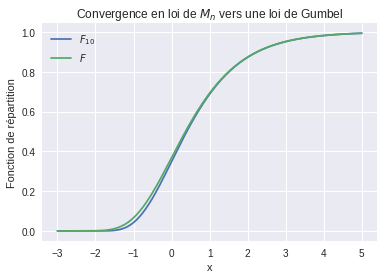

In [18]:
# Answer
n = 10
x = np.linspace(-3, 5, num=200)
# Compléter
Fn = (1-np.exp(-x)/n)**n * (x > -np.log(n))

plt.plot(x, Fn, label=f"$F_{{{n}}}$")
plt.plot(x, np.exp(-np.exp(-x)), label="$F$")
# Fin compléter
plt.legend()
plt.xlabel('x')
plt.ylabel('Fonction de répartition')
plt.title("Convergence en loi de $M_n$ vers une loi de Gumbel");

# Exercice 6 : Comparaison d'estimateurs <a id="part6"></a>
>Soit $X$ une variable aléatoire réelle de densité $f_{\theta^\star}$, où $\theta^\star \in \mathbb R_+^*$ est inconnu et pour tout $\theta > 0$,
$$f_\theta : x \in \mathbb R \mapsto \frac{1}{\theta} \exp \left( -\frac{x-\theta}{\theta} \right) \mathbb 1_{[\theta, +\infty[}(x).$$
$X$ suit donc une loi exponentielle translatée de $\theta^\star$ et dilatée de $\theta^\star$.
Autrement dit, $\frac{X-\theta^\star}{\theta^\star} \sim \mathcal{E}(1)$.
>
>On suppose que l'on dispose d'un $n$-échantillon $\mathbf X = (X_1, \dots, X_n)$ dont les variables aléatoires sont distribuées identiquement à $X$.
Soient les trois estimateurs suivants de $\theta^\star$:
$$
		T_{1, n}(\mathbf X) = \frac{1}{2n} \sum_{i=1}^n X_i,
		\qquad
		T_{2, n}(\mathbf X) = \frac{x_{1/2}(n)}{1+\ln(2)} % x_{1/2}(n)
		\quad \text{et} \quad
		T_{3, n}(\mathbf X) = \min_{1 \le i \le n} X_i,
$$
où $x_{1/2}(n)$ est la médiane empirique de  $\mathbf X$.
>
>**Question 1.**
Pour les illustrations numériques, considérons que le paramètre inconnu vaut $\theta^\star=4$.
Tracer la densité de $X$.
Afficher l'espérance et la variance de $X$ et vérifier que les résultats sont cohérents avec les valeurs théoriques.

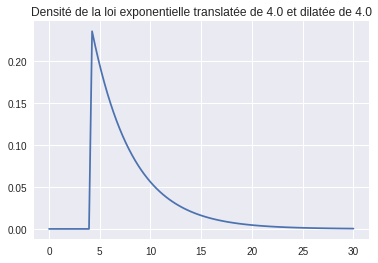

In [19]:
# Answer
from scipy.stats import expon

theta = 4.
# Compléter
dist = expon(loc=theta, scale=theta)

t = np.linspace(0, 30, num=100)
plt.plot(t, dist.pdf(t))
# Fin compléter
plt.title(f'Densité de la loi exponentielle translatée de {theta} et dilatée de {theta}');

In [20]:
# Answer
print("Espérance :", dist.mean())
print("Variance :", dist.var())

Espérance : 8.0
Variance : 16.0


>**Question 2.**
Considérons que $n=200$.
Tirer aléatoirement un échantillon de taille $n$ selon la loi de $X$ et calculer les réalisations des trois estimateurs.
Afficher leurs valeurs.
>
>Indication : la médiane empirique d'un échantillon $\mathbf X$ s'obtient par la commande `np.quantile(X, 0.5, interpolation='lower')` ou `np.percentile(x, 50, interpolation='lower')`.

In [21]:
# Answer
n = 200

x = dist.rvs(size=n)
T1 = x.mean() / 2
T2 = np.quantile(x, 0.5, interpolation='lower') / (1+np.log(2))
T3 = x.min()

print(T1, T2, T3)

4.126071424020342 3.8230445488300955 4.009151189343377


/tmp/ipykernel_26270/3433136725.py:6: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  T2 = np.quantile(x, 0.5, interpolation='lower') / (1+np.log(2))


>**Question 3.**
Soit $N=1000$.
Tirer aléatoirement $N$ échantillons $\mathbf X_1, \dots, \mathbf X_N$ de taille $n$ de manière indépendante et identiquement distribuée à $\bf X$.
Calculer puis afficher une estimation du risque quadratique de chacun des trois estimateurs $T_{k, n}$ ($k \in \{1, 2, 3\}$) :
$$
    R_{k, n} = \frac{1}{N} \sum_{j=1}^N (T_{k, n}(\mathbf X_j) - \theta^\star)^2.
$$

In [22]:
# Answer
N = 1000

x = dist.rvs(size=(n, N))
T1 = x.mean(axis=0) / 2
T2 = np.quantile(x, 0.5, interpolation='lower', axis=0) / (1+np.log(2))
T3 = x.min(axis=0)

for label, T in [('Moyenne', T1), ('Médiane', T2), ('Minimum', T3)]:
    print(label, ":", np.mean((T-theta)**2))

Moyenne : 0.019548650502138564
Médiane : 0.02869829431795479
Minimum : 0.0007520913914856595


/tmp/ipykernel_26270/630494486.py:6: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  T2 = np.quantile(x, 0.5, interpolation='lower', axis=0) / (1+np.log(2))


>**Question 4.**
Répéter cette opération pour plusieurs valeurs de $n$ comprises entre 10 et 200 puis afficher (avec une échelle logarithmique en x et y) l'évolution du risque quadratique estimé $R_{k, n}$ ($k \in \{1, 2, 3\}$) en fonction de $n$.
Quel estimateur vous semble préférable ?

/tmp/ipykernel_26270/187539129.py:9: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  T2 = np.quantile(x, 0.5, interpolation='lower', axis=0) / (1+np.log(2))


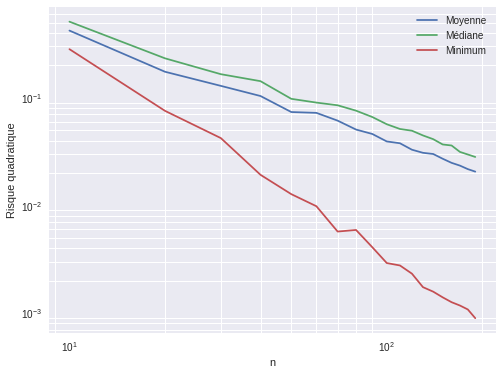

In [23]:
# Answer
R1 = []
R2 = []
R3 = []
n_values = np.arange(10, 200, 10)
for n in n_values:
    x = dist.rvs(size=(n, N))
    T1 = x.mean(axis=0) / 2
    T2 = np.quantile(x, 0.5, interpolation='lower', axis=0) / (1+np.log(2))
    T3 = x.min(axis=0)
    
    for R, T in [(R1, T1), (R2, T2), (R3, T3)]:
        R.append(np.mean((T-theta)**2))

plt.figure(figsize=(8, 6))
for R, T, label in [(R1, T1, "Moyenne"), (R2, T2, "Médiane"), (R3, T3, "Minimum")]:
    plt.plot(n_values, R, label=label)
plt.xlabel('n')
plt.ylabel('Risque quadratique')
plt.legend(loc="best")
plt.xscale("log")
plt.yscale("log")
plt.grid(which="both")

# Exercice 7 : Fonction de répartition empirique <a id="part7"></a>
> On considère une suite de variables aléatoires $(X_i)_{i\geq 1}$ i.i.d. suivant une loi de Cauchy dont la fonction de répartition est notée $F$. Pour tout $n\geq 1$ et tout réel $x$, on considère la fonction de répartition empirique 
$$F_n(x):=\frac{1}{n}\sum_{i=1}^n\mathbf{1}_{X_i\leq x}.$$
Illustrer la convergence de $F_n$ vers $F$. On pourra utiliser la classe `ECDF` du module `statsmodels.distributions.empirical_distribution`.

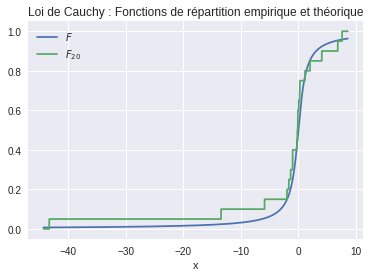

In [24]:
# Answer
from statsmodels.distributions.empirical_distribution import ECDF

n = 20
dist = stats.cauchy()

# Compléter
X = dist.rvs(size=n)
x = np.arange(X.min()-1, X.max()+1, step=0.01)

ecdf = ECDF(X)

plt.plot(x, stats.cauchy.cdf(x), label=r"$F$")
plt.plot(x, ecdf(x), label=r"$F_{%d}$" % n)
# Fin compléter
plt.xlabel('x')
plt.legend()
plt.title("Loi de Cauchy : Fonctions de répartition empirique et théorique");

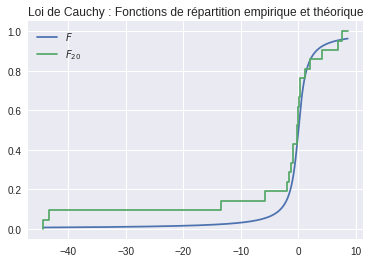

In [25]:
# Answer
# n = 20
# X = stats.cauchy.rvs(size=n)
# x = np.arange(X.min()-1, X.max()+1, step=0.01)

# Efficient method
y_cdf = np.r_[np.arange(0, n+1), n+1] / (n+1)
x_cdf = np.r_[x[0], np.sort(X), x[-1]]

plt.plot(x, stats.cauchy.cdf(x), label=r"$F$")
plt.step(x_cdf, y_cdf, label=r"$F_{%d}$" % n)
plt.legend()
plt.title("Loi de Cauchy : Fonctions de répartition empirique et théorique");

## Exercice 8 : Estimateur, test et fonction puissance <a id="part7sec1"></a>
>**Question 1.**
Soient $\theta = 2$ et $(X_1, \dots, X_n)$ un $n$-échantillon distribué selon $\mathcal{E}(\theta)$.
On suppose $n=50$.
Générer une réalisation de $(X_1, \dots, X_n)$.
Afficher un histogramme de cette réalisation et superposer la densité de probabilité.

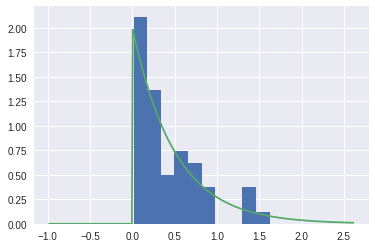

In [26]:
# Answer
theta = 2
n = 50

dist = stats.expon(scale = 1/theta)
X = dist.rvs(size=n)

x = np.arange(X.min()-1, X.max()+1, step=0.01)

plt.hist(X, bins=10, density=True)  # normed=True for old versions
plt.plot(x, dist.pdf(x));

>**Question 2.**
Donner un estimateur $\hat \theta_n$ de $\theta$ par la méthode des moments et calculer sa réalisation.

**Answer**

Puisque $\mathbb{E}_\theta[X_1]=1/\theta$, on considère l'estimateur $\hat \theta_n:=1/\bar X_n$.

In [27]:
# Answer
estim = 1/X.mean()
print("Estimation :", estim)

Estimation : 2.3616557966947154


>**Question 2.**
On souhaite tester $H_0 : \theta = 1$ contre $H_1 : \theta \neq 1$.
Construire un test de niveau asymptotique $\alpha$ (avec $\alpha = 5\%$) pour les hypothèses précédentes.
Afficher sa réalisation et la $p$-valeur associée.
Conclure.

**Answer**

On a 
$$\sqrt n \left(\bar X_n - \frac 1 \theta\right) \xrightarrow[n \to \infty]{\mathcal L} \mathcal N \left(0, \frac{1}{\theta^2}\right).$$
Par la méthode delta, 
$$\sqrt n \left(\frac{\hat \theta_n}{\theta} - 1\right) \xrightarrow[n \to \infty]{\mathcal L} \mathcal N(0, 1)$$
et en particulier, sous $H_0$, 
$$\sqrt n \left(\hat \theta_n - 1\right) \xrightarrow[n \to \infty]{\mathcal L} \mathcal N(0, 1).$$
Soit $q$ le $(1-\frac \alpha 2)$-quantile de la loi $\mathcal N(0, 1)$.
Alors $I = \left[\hat \theta_n \pm \frac{q}{\sqrt n} \right]$ est un intervalle de confiance de niveau asymptotique $(1-\alpha)$ pour 1
et $T = \mathbb 1_{1 \notin I} = \mathbb 1_{|\hat \theta_n - 1| > \frac{q}{\sqrt n}}$ est un test de niveau asymptotique $\alpha$ pour $H_0$.

Pour une réalisation $t$ de $\hat \theta_n$, la $p$-valeur associée au test est $\alpha_0 = 2(1 - \Phi(\sqrt n |t - 1|))$.

In [28]:
# Answer
norm = stats.norm()
q = norm.ppf(1-0.05/2)
T = int(np.abs(estim - 1) > q / np.sqrt(n))  # Test
p = 2 * (1 - norm.cdf(np.sqrt(n) * np.abs(estim-1)))  # p-value
print("Test :", T)
print("Interprétation :", r"on rejette H0" if T else "on conserve H0")
print("p-valeur :", p)

Test : 1
Interprétation : on rejette H0
p-valeur : 0.0


>**Question 3.**
Pour $n$ grand, calculer et représenter une approximation de la fonction puissance $\pi_n(\theta)$ associée à ce test pour $\theta$ variant entre 0 et 5.

**Answer**

Pour tout $\theta>0$, la puissance est $\pi_n(\theta) = \mathbb P_\theta(T=1)$. Or, on a vu ci-dessus que
$$\sqrt n \left(\frac{\hat \theta_n}{\theta} - 1\right) \xrightarrow[n \to \infty]{\mathcal L} \mathcal N(0, 1).$$
L'approximation de la fonction puissance consiste à considérer qu'il y a égalité en loi dans ce résultat. 

Rappelons qu'on accepte $H_0$ si et seulement si 
$$-\frac{q}{\sqrt n}\leq \hat \theta_n - 1 \leq \frac{q}{\sqrt n},$$
autrement dit si et seulement si
$$\sqrt{n}\left(\frac{1}{\theta}\left(1-\frac{q}{\sqrt n}\right)-1\right)\leq \sqrt n \left(\frac{\hat \theta_n}{\theta} - 1\right)\overset{{\cal L}}{\approx}\mathcal N(0, 1)\leq \sqrt{n}\left(\frac{1}{\theta}\left(1+\frac{q}{\sqrt n}\right)-1\right).$$
Ainsi, la fonction puissance s'écrit
$$\pi_n(\theta)= 1 - \mathbb P \left[ \sqrt n \left(\frac 1 \theta - \frac{q}{\theta \sqrt n} - 1 \right) \le \sqrt n \left(\frac{\hat \theta_n}{\theta} - 1 \right) \le \sqrt n \left(\frac 1 \theta + \frac{q}{\theta \sqrt n} - 1 \right) \right] \approx 1 - \Phi\left(\sqrt n \left(\frac 1 \theta - 1 \right) + \frac{q}{\theta} \right) + \Phi\left(\sqrt n \left(\frac 1 \theta - 1 \right) - \frac{q}{\theta} \right).$$

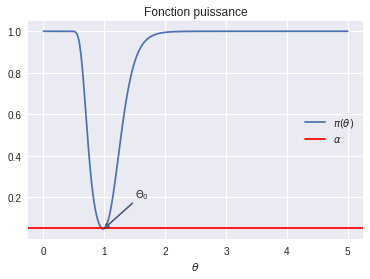

In [29]:
# Answer
x = np.linspace(1e-5, 5, num=500)
power = 1 - norm.cdf(np.sqrt(n) * (1/x - 1) + q / x) + norm.cdf(np.sqrt(n) * (1/x - 1) - q / x)

plt.plot(x, power, label='$\\pi(\\theta)$')
plt.axhline(5e-2, color='red', label="$\\alpha$")
plt.legend()
plt.xlabel('$\\theta$')
plt.title('Fonction puissance')
plt.annotate('$\\Theta_0$', xy=(1, 5e-2), xytext=(1.5, .2), arrowprops=dict(width=1, headwidth=5, headlength=5));

>**Question 4.**
Que se passe-t-il lorsque $n$ grandit ?

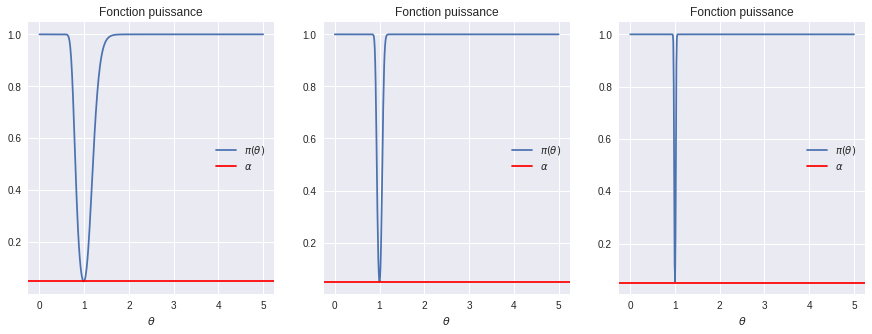

In [30]:
# Answer
plt.figure(figsize=(15, 5))
for i, n in enumerate([100, 1000, 10000]):
    power = 1 - norm.cdf(np.sqrt(n) * (1/x - 1) + q / x) + norm.cdf(np.sqrt(n) * (1/x - 1) - q / x)

    plt.subplot(1, 3, i+1)
    plt.plot(x, power, label='$\\pi(\\theta)$')
    plt.axhline(5e-2, color='red', label="$\\alpha$")
    plt.legend()
    plt.xlabel('$\\theta$')
    plt.title('Fonction puissance')

**Answer**

Comme attendu, la suite de fonctions puissances $\pi_n(\theta)$ semble converger simplement vers $\alpha\mathbb 1_{\theta=1}+\mathbb 1_{\theta\neq1}$.